# HAR CNN Training — Aryan
**Run this notebook on Google Colab with GPU (Runtime → Change runtime type → T4 GPU)**

What this notebook does:
1. Clones the GitHub repo
2. Downloads and processes the UCI HAR dataset via Akhil's `data.py`
3. Trains the 1-D CNN defined in `src/train_cnn.py`
4. Saves `models/cnn.keras` and `results/cnn_metrics.json`
5. Downloads the output files so you can commit them from your laptop

## Step 1 — Clone the repo

In [7]:
import os

REPO_URL    = 'https://github.com/aryan-2206/Human_Activity_Recognition.git'
BRANCH      = 'aryan-cnn'
REPO_DIR    = '/content/Human_Activity_Recognition'

if os.path.exists(REPO_DIR):
    %cd {REPO_DIR}
    !git pull origin {BRANCH}
else:
    !git clone --branch {BRANCH} {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}

# Add repo root to Python path so src.* imports work
import sys
sys.path.insert(0, REPO_DIR)
print('Working directory:', os.getcwd())

/content/Human_Activity_Recognition
From https://github.com/aryan-2206/Human_Activity_Recognition
 * branch            aryan-cnn  -> FETCH_HEAD
Already up to date.
Working directory: /content/Human_Activity_Recognition


## Step 2 — Install dependencies

In [8]:
# Colab already has TensorFlow. Install any extras.
!pip install -q joblib scikit-learn matplotlib

import tensorflow as tf
print('TensorFlow:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 3 — Download and process data (Akhil's data.py)

In [9]:
from src.data import prepare_data
X_train, X_test, y_train, y_test, subjects_train, subjects_test = prepare_data()

print(f'X_train: {X_train.shape}  y_train: {y_train.shape}')
print(f'X_test : {X_test.shape}   y_test : {y_test.shape}')

train: X=(7352, 128, 6), y=(7352,), counts={'WALKING': 1226, 'WALKING_UPSTAIRS': 1073, 'WALKING_DOWNSTAIRS': 986, 'SITTING': 1286, 'STANDING': 1374, 'LAYING': 1407}
test: X=(2947, 128, 6), y=(2947,), counts={'WALKING': 496, 'WALKING_UPSTAIRS': 471, 'WALKING_DOWNSTAIRS': 420, 'SITTING': 491, 'STANDING': 532, 'LAYING': 537}
X_train: (7352, 128, 6)  y_train: (7352,)
X_test : (2947, 128, 6)   y_test : (2947,)


## Step 4 — Build and inspect the CNN

In [10]:
from src.train_cnn import build_cnn

model = build_cnn(input_shape=(128, 6))
model.summary()

Model: "CNN_HAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 128, 6)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 128, 64)        │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling1D)            │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling1D)            │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 32, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 256)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling1D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop4 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,094 (691.77 KB)

 Trainable params: 176,198 (688.27 KB)

 Non-trainable params: 896 (3.50 KB)

## Step 5 — Train the CNN

In [11]:
# Runs train_cnn.py's train() — saves model + metrics automatically
from src.train_cnn import train
train(epochs=25, batch_size=64)

[train_cnn] Loading data...
  X_train: (7352, 128, 6)  y_train: (7352,)
  X_test : (2947, 128, 6)   y_test : (2947,)


Model: "CNN_HAR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 128, 6)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv1D)                  │ (None, 128, 64)        │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 128, 64)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling1D)            │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv1D)                  │ (None, 64, 128)        │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 64, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling1D)            │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv1D)                  │ (None, 32, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 256)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling1D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop4 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,094 (691.77 KB)

 Trainable params: 176,198 (688.27 KB)

 Non-trainable params: 896 (3.50 KB)


[train_cnn] Training for up to 25 epochs, batch size 64...
Epoch 1/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.7533 - loss: 0.6127
Epoch 1: val_accuracy improved from None to 0.85462, saving model to /content/Human_Activity_Recognition/models/cnn.keras

Epoch 1: finished saving model to /content/Human_Activity_Recognition/models/cnn.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 29s 146ms/step - accuracy: 0.8623 - loss: 0.3508 - val_accuracy: 0.8546 - val_loss: 0.4518 - learning_rate: 0.0010
Epoch 2/25
101/104 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9397 - loss: 0.1646
Epoch 2: val_accuracy improved from 0.85462 to 0.91712, saving model to /content/Human_Activity_Recognition/models/cnn.keras

Epoch 2: finished saving model to /content/Human_Activity_Recognition/models/cnn.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9401 - loss: 0.1565 - val_accuracy: 0.9171 - val_loss: 0.1887 - learning_rate: 0.0010
Epoch 3/25
 99/104 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accur

## Step 6 — Verify outputs

Model    : CNN
Accuracy : 0.9145
F1 macro : 0.9135


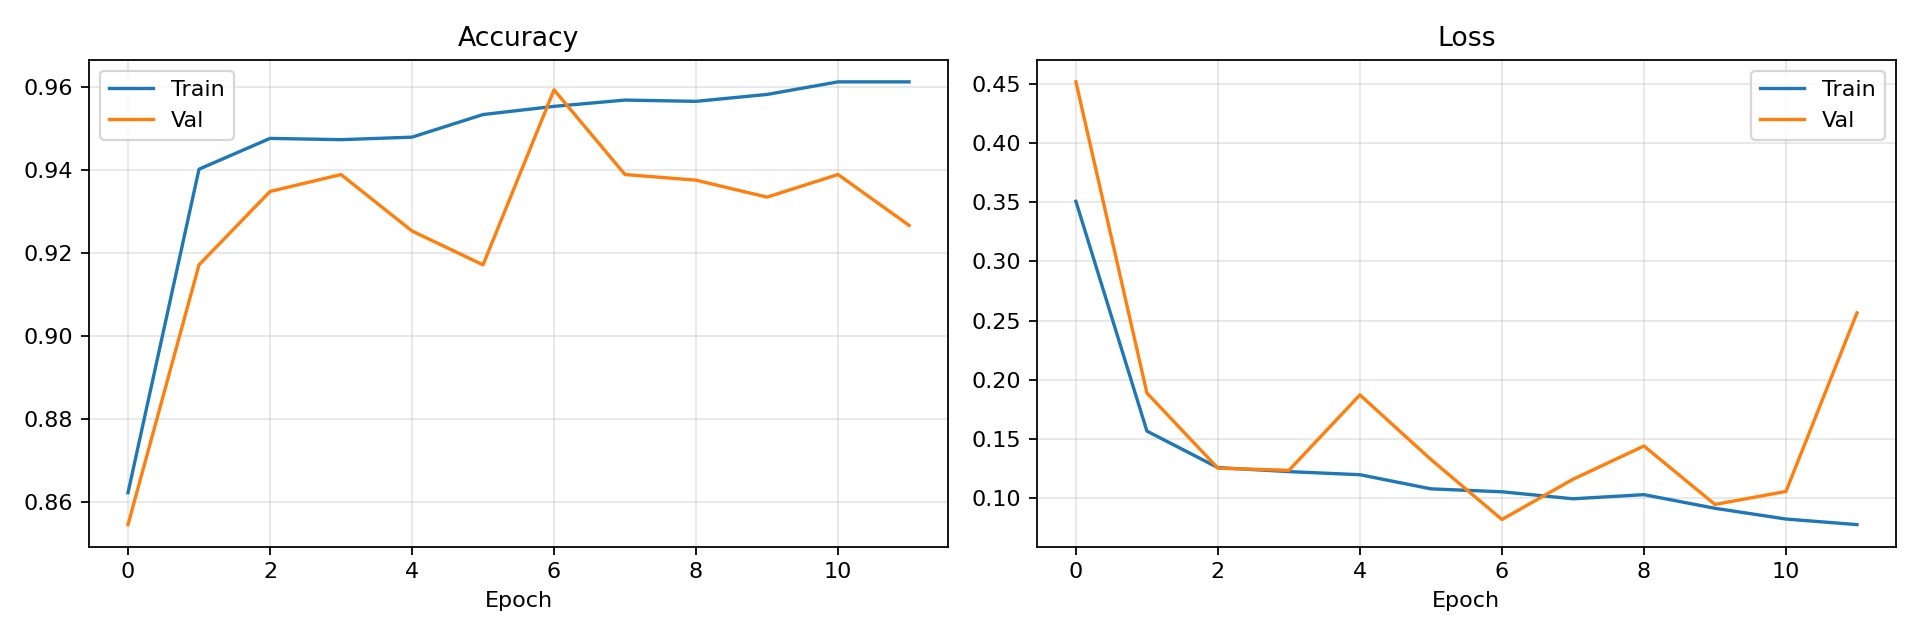

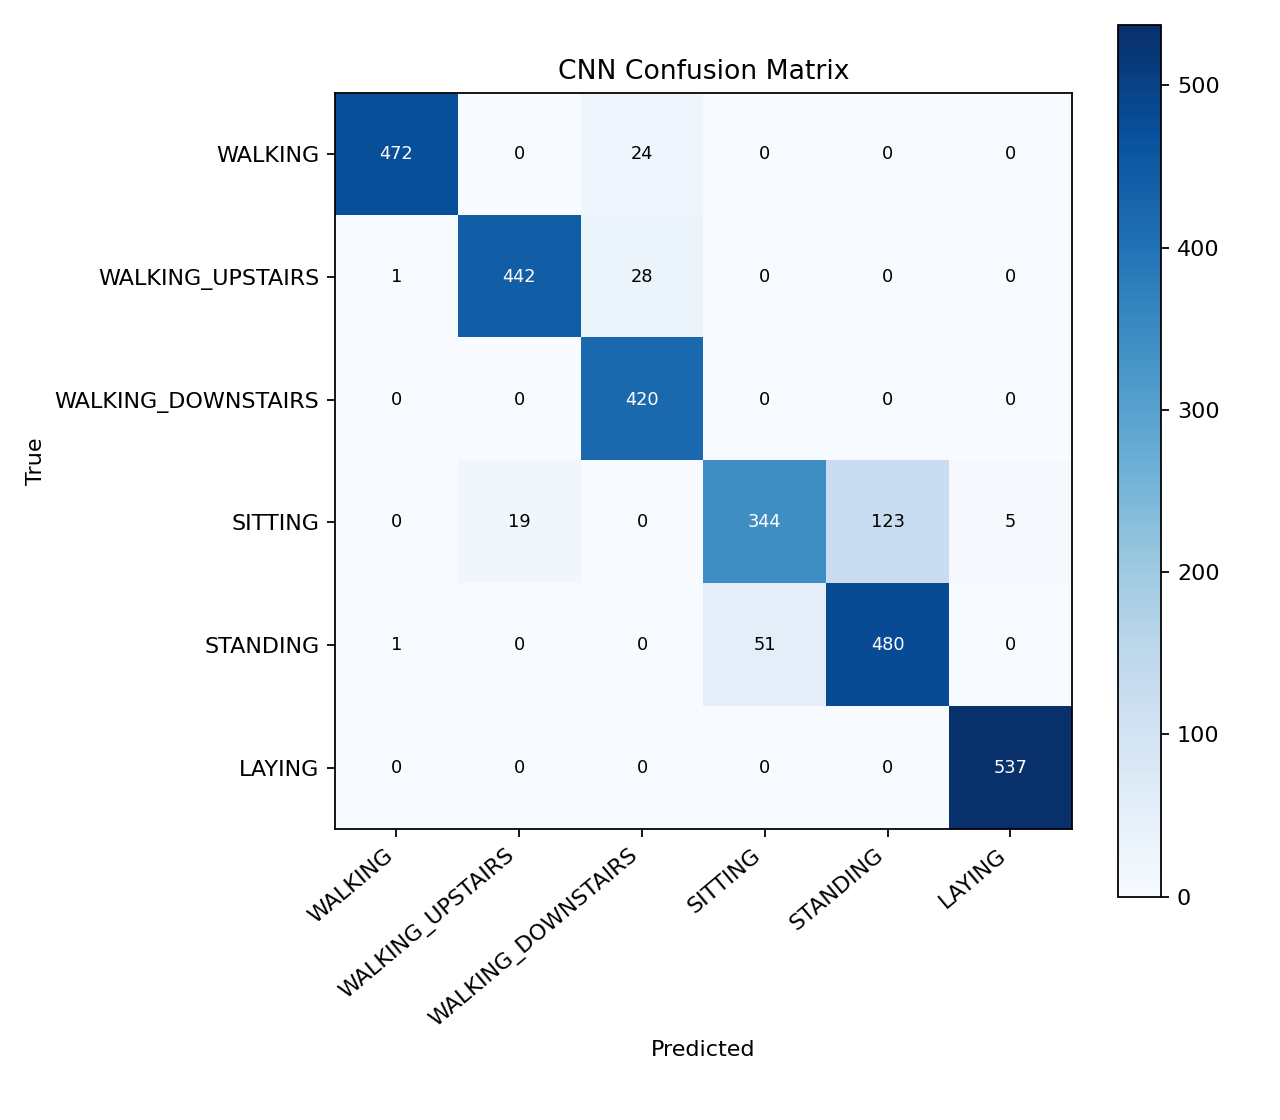

In [12]:
import json
from pathlib import Path

metrics = json.loads(Path('results/cnn_metrics.json').read_text())
print('Model    :', metrics['model'])
print('Accuracy :', round(metrics['accuracy'], 4))
print('F1 macro :', round(metrics['f1_macro'], 4))

from IPython.display import Image, display
display(Image('results/cnn_training_history.png'))
display(Image('results/cnn_confusion.png'))

## Step 7 — Download output files to your laptop
Run this cell, then commit the downloaded files from your laptop:
```bash
git checkout aryan-cnn
# copy the downloaded files into models/ and results/
git add models/cnn.keras results/cnn_metrics.json results/cnn_confusion.png results/cnn_training_history.png
git commit -m "feat: trained CNN — accuracy X.XX"
git push origin aryan-cnn
```

In [13]:
from google.colab import files

files.download('models/cnn.keras')
files.download('results/cnn_metrics.json')
files.download('results/cnn_confusion.png')
files.download('results/cnn_training_history.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## (Optional) Step 8 — Smoke-test predict.py

In [14]:
from src.predict import predict_all, LABELS
import numpy as np

X_test = np.load('data/processed/X_test.npy')
y_test = np.load('data/processed/y_test.npy')

preds = predict_all(X_test, verbose=True)
for name, p in preds.items():
    acc = (p == y_test).mean()
    print(f'{name:5s}: {acc:.4f}')

[predict] CNN: 2604.6ms for 2947 samples
CNN  : 0.9145
